# Can run luck be estimated from 1 run of our own agents?

- This notebook is the test of Study B in `preregistration_2.md`: the 1-run
  estimator tuned on the public EvalPlus samples in `skill_vs_luck.one_run`
  is applied once to our runs
  - The tuned setting, `TUNED_ONE_RUN_SETTING`, was committed before any of
    our runs went into the estimator
- Each of the 30 cases is 1 of our agents on 1 benchmark at 1 temperature:
  - Phase 1: the 6 old agents at 0.8 on both benchmarks, 12 cases whose run
    shares were known when the estimator was tuned
  - Phase 2: the 6 new agents at 0.8 on both benchmarks and the 6 old agents
    at 0.2 on HumanEval+, 18 cases that decide the predictions
- The estimate of a case comes from run 1 of its agent and of the one-shot
  agents of the other models with the same benchmark and temperature, and
  its truth from all the runs of its agent
- The pedagogical arc:
  - The 30 cases
  - The estimates from 1 run, before and after tuning
  - Which predictions held
  - How many tasks need a second run

In [1]:
%load_ext autoreload
%autoreload 2

import logging

In [2]:
import helpers.hnotebook as hnotebook

import skill_vs_luck_runs_utils as rutils

# Initialize notebook configuration and logging.
hnotebook.config_notebook()
_LOG = logging.getLogger(__name__)
rutils.init_loggers(_LOG)

# Convert `display` into `print()` when running outside IPython.
try:
    from IPython.display import display
except ImportError:
    display = print  # type: ignore

/usr/local/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


INFO  > /usr/local/lib/python3.12/site-packages/ipykernel_launcher.py -f /tmp/tmpnm7a7u0q.json --HistoryManager.hist_file=:memory:


# Part 1: The test cases

## Cell 1.1: Load the scores of both phases

- Phase 1 has the runs at 0.8 of the old models, and phase 2 the runs at 0.8
  of the new models and the runs at 0.2 of the old models
- The public samples are not loaded: neither setting uses extra agents

In [3]:
# Read the local scores of both phases and list the 30 cases.
PHASE_1_DIR = "data/coding_runs"
PHASE_2_DIR = "data/coding_runs_phase2"
old_scores = rutils.load_scores(PHASE_1_DIR, pattern="local_*.csv.gz")
new_scores = rutils.load_scores(PHASE_2_DIR)
scores = rutils.combine_scores(old_scores, new_scores)
cases = rutils.get_one_run_cases()

print("scores.shape=", scores.shape)
display(cases.groupby(["phase", "benchmark", "temperature"]).size())
# Outcome: 36,456 rows from both phases and the 30 cases: 12 from phase 1 at
# 0.8, and 18 from phase 2, 12 at 0.8 and 6 at 0.2 on HumanEval+.

scores.shape= (36456, 19)


phase  benchmark  temperature
1      humaneval  0.8            6
       mbpp       0.8            6
2      humaneval  0.2            6
                  0.8            6
       mbpp       0.8            6
dtype: int64

# Part 2: The estimates from 1 run

## Cell 2.1: Estimate every case before and after tuning

- Before tuning: Rasch with the penalty 0.01 and no calibration
- After tuning: 2PL with the penalty 0.1 and the factor 1.344
- Both settings see the same matrices, with no extra agents
- `n_runs` is the number of runs behind the truth: 5 for the phase-1 cases
  and 3 for the phase-2 ones

In [4]:
# Estimate the run share of every case from 1 run, with both settings.
SETTINGS = {
    "untuned": rutils.UNTUNED_ONE_RUN_SETTING,
    "tuned": rutils.TUNED_ONE_RUN_SETTING,
}
results = rutils.estimate_one_run_cases(scores, cases, SETTINGS)

display(results.round(3))
# Outcome: the estimates are 0.36 to 0.51 before tuning and 0.26 to 0.56 after,
# for truths from 0.15 to 0.53. Within a temperature and a benchmark they move
# little from agent to agent: at 0.2 the tuned ones are 0.26 to 0.30, for
# truths of 0.15 to 0.21.

  0%|          | 0/30 [00:00<?, ?it/s]

 10%|█         | 3/30 [00:00<00:01, 21.84it/s]

 20%|██        | 6/30 [00:00<00:01, 19.73it/s]

 27%|██▋       | 8/30 [00:00<00:01, 16.61it/s]

 33%|███▎      | 10/30 [00:00<00:01, 14.04it/s]

...

 73%|███████▎  | 22/30 [00:01<00:00, 14.30it/s]

 80%|████████  | 24/30 [00:01<00:00, 13.62it/s]

 93%|█████████▎| 28/30 [00:01<00:00, 18.61it/s]

100%|██████████| 30/30 [00:01<00:00, 17.13it/s]

,phase,benchmark,temperature,model,scaffold,n_runs,truth,untuned,tuned
0,1,humaneval,0.8,deepseek-coder:1.3b-instruct-q4_K_M,one_shot,5,0.416,0.510,0.557
1,1,humaneval,0.8,deepseek-coder:1.3b-instruct-q4_K_M,repair,5,0.397,0.505,0.554
2,1,humaneval,0.8,codeqwen:7b-chat-v1.5-q4_K_M,one_shot,5,0.520,0.448,0.441
3,1,humaneval,0.8,codeqwen:7b-chat-v1.5-q4_K_M,repair,5,0.496,0.428,0.430
4,1,humaneval,0.8,opencoder:8b,one_shot,5,0.370,0.443,0.482
5,1,humaneval,0.8,opencoder:8b,repair,5,0.377,0.443,0.490
6,1,mbpp,0.8,deepseek-coder:1.3b-instruct-q4_K_M,one_shot,5,0.378,0.404,0.405
7,1,mbpp,0.8,deepseek-coder:1.3b-instruct-q4_K_M,repair,5,0.365,0.406,0.415
8,1,mbpp,0.8,codeqwen:7b-chat-v1.5-q4_K_M,one_shot,5,0.376,0.385,0.433
9,1,mbpp,0.8,codeqwen:7b-chat-v1.5-q4_K_M,repair,5,0.367,0.385,0.436


## Cell 2.2: Errors by phase and temperature

- `untuned_error` and `tuned_error` are the mean absolute errors; on the
  development set the tuned setting had a cross-validated error of 5.6
  points, picked as the best of 21 settings, so that number is optimistic
- `within` is the share of the cases whose tuned estimate is within 10
  points of the truth, the rule of B1
- `above` is the share of the cases whose estimate before tuning is above
  the truth, the rule of B2

In [5]:
# Summarize the cases of each phase and temperature.
summary = rutils.summarize_one_run_test(
    results, tuned="tuned", untuned="untuned"
)

display(summary.round(3))
# Outcome: on the 18 phase-2 cases the tuned estimate is off by 9.6 points on
# average at 0.2 and by 10.5 at 0.8, close to twice the 5.6 points of the
# development set. Tuning helps at 0.2, where the error before tuning is 20.6
# points, and hurts at 0.8, where the estimate before tuning is already too
# high (0.449 against a truth of 0.374) and the factor 1.344 raises it to
# 0.479. On the 12 phase-1 cases the tuned error is 8.8 points.

cases  truth  untuned  tuned  untuned_error  tuned_error  within  above
phase temperature                                                                         
1     0.8             12  0.386    0.425  0.450          0.062        0.088   0.667  0.833
2     0.2              6  0.188    0.394  0.283          0.206        0.096   0.667  1.000
      0.8             12  0.374    0.449  0.479          0.085        0.105   0.250  0.833

## Cell 2.3: Plot the estimates against the truth

- Each point is 1 case; the hollow ones are the phase-1 cases, whose run
  shares were known when the estimator was tuned
- Points in the gray band are within 10 points of the truth

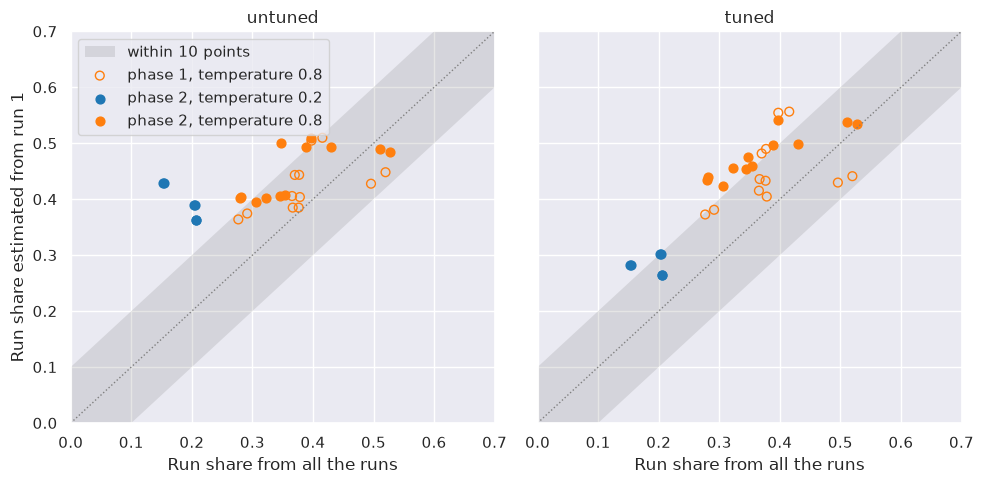

In [6]:
# Plot both settings.
rutils.plot_one_run_test(results, list(SETTINGS), figsize=(10, 5))
# Outcome: after tuning, the cases at 0.2 move close to the band, but most of
# the phase-2 cases at 0.8 sit above it, all 6 on MBPP+ among them.

# Part 3: Which predictions held?

## Cell 3.1: Predictions against the results

- Both predictions are decided on the 18 phase-2 cases only

In [7]:
# Check B1 and B2.
predictions = rutils.check_one_run_predictions(
    results, tuned="tuned", untuned="untuned"
)

display(predictions)
# Outcome: B1 does not hold: 7 of the 18 phase-2 tuned estimates are within 10
# points (4 of 6 at 0.2 and 3 of 12 at 0.8), short of the 12 we predicted. B2
# holds: before tuning, 16 of the 18 estimates are above the truth (all 6 at
# 0.2 and 10 of 12 at 0.8).

,prediction,observed,holds
B1,The tuned estimate is within 10 points for at ...,7 of 18 within 10 points,False
B2,The estimate before tuning is above the truth ...,16 of 18 above the truth,True


# Part 4: How many tasks need a second run?

## Cell 4.1: Second runs on some tasks

- As in Part 4 of `skill_vs_luck.one_run`: the first 2 runs of a case play
  the 2 runs, and the number shown is the smallest number of tasks with a
  second run such that 95% of the random picks of those tasks are within 10
  points of the truth
- NaN means that even a second run of every task is not enough

In [8]:
# Find how many tasks need a second run in each case.
second_runs = rutils.compute_second_run_cases(scores, cases)

display(second_runs)
# Outcome: to be within 10 points 95% of the time, 81 to 109 of the 164
# HumanEval+ tasks need a second run at 0.2, 104 to 159 at 0.8, and 141 to 200
# of the 378 MBPP+ tasks at 0.8. In 3 cases, all on HumanEval+ at 0.8
# (CodeQwen 7B with both scaffolds and DeepSeek-Coder 6.7B one-shot), even a
# second run of every task is not enough.

,phase,benchmark,temperature,model,scaffold,n_tasks,second_run_tasks
0,1,humaneval,0.8,deepseek-coder:1.3b-instruct-q4_K_M,one_shot,164,114.0
1,1,humaneval,0.8,deepseek-coder:1.3b-instruct-q4_K_M,repair,164,123.0
2,1,humaneval,0.8,codeqwen:7b-chat-v1.5-q4_K_M,one_shot,164,NaN
3,1,humaneval,0.8,codeqwen:7b-chat-v1.5-q4_K_M,repair,164,NaN
4,1,humaneval,0.8,opencoder:8b,one_shot,164,129.0
5,1,humaneval,0.8,opencoder:8b,repair,164,152.0
6,1,mbpp,0.8,deepseek-coder:1.3b-instruct-q4_K_M,one_shot,378,155.0
7,1,mbpp,0.8,deepseek-coder:1.3b-instruct-q4_K_M,repair,378,147.0
8,1,mbpp,0.8,codeqwen:7b-chat-v1.5-q4_K_M,one_shot,378,166.0
9,1,mbpp,0.8,codeqwen:7b-chat-v1.5-q4_K_M,repair,378,166.0


# Part 5: Takeaways

- The 1-run estimator failed its test: prediction B1 missed, with 7 of the 18
  new cases within 10 points against the 12 we predicted
- Prediction B2 held: without tuning, the estimate is above the truth in 16
  of the 18 cases, since it counts what an agent is good at as luck
- The tuning carried over at 0.2 but not at 0.8:
  - At 0.8 the estimate before tuning is about the same on the public
    samples (47.5% in `skill_vs_luck.one_run`) and on our new cases (44.9%),
    but the truth is lower on ours (37.4% against 50.3%)
  - So the factor 1.344 that fixed the public samples overshoots our runs
- As on the development set, the estimates follow the temperature and the
  benchmark more than the agent, so 1 run gives a rough level of run luck for
  a setting, not a number for each agent
- Measuring run luck to within 10 points still takes a second run of 37% to
  97% of the tasks, and in 3 cases even a second run of every task falls
  short